# C1 anomaly detection: data exploration

Profiles the cleaned predictive-maintenance dataset and prototypes the features
used by the anomaly detector: per-mode z-scores, a resolution gap, and a causal
fleet-share index. The HDBSCAN section at the end is an experiment kept for
reference, not the retained approach.


In [168]:
import pandas as pd
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    """Walk up from ``start`` until the repository root is found."""
    for base in (start, *start.parents):
        if (base / "pyproject.toml").is_file() and (base / "data").is_dir():
            return base
    raise FileNotFoundError(
        f"Repository root not found from {start}. "
        "Open the notebook from inside the repository."
    )


# This notebook lives in services/c1-sensor-quality/src/c1_sensor_quality/
# anomaly_detector, so resolve paths from the repository root.
REPO_ROOT = find_repo_root(Path.cwd())
DATA_FILE = REPO_ROOT / "data/processed/cleaned_predictive_maintenance_data.csv"
# DATA_FILE = REPO_ROOT / "data/raw/predictive_maintenance_data.csv"
MODEL_DIR = REPO_ROOT / "models/c1-sensor-quality"

df = pd.read_csv(DATA_FILE, parse_dates=["timestamp"], low_memory=False)
print(f"{DATA_FILE} -> {df.shape[0]:,} rows x {df.shape[1]} columns")


/mnt/D6A44CAEA44C92C3/Documents/documents Pierre/ecole/UTT/ISI/étranger/A26/cours/developing AI enabled systems/project/data/processed/cleaned_predictive_maintenance_data.csv -> 525,600 rows x 20 columns


In [169]:
df.head()

,timestamp,machine_id,operating_mode,temperature,vibration,pressure,rpm,power,anomaly,anomaly_type,failure_probability_gt,failure_in_7_days,remaining_useful_life_hours,failure_type,important_features,maintenance_action,priority,concept_drift_active,quality_disposition,quality_flags
0,2012-01-14 00:00:00,M001,HIGH_LOAD,46.075260,1.646840,98.800597,2188.426973,316.167708,False,normal,0.036871,False,963.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none
1,2012-01-14 01:00:00,M001,NORMAL,39.162895,1.250197,99.416209,1523.071068,201.667279,False,normal,0.037255,False,962.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none
2,2012-01-14 02:00:00,M001,HIGH_LOAD,42.957758,1.464074,99.556791,2265.053310,313.975128,False,normal,0.038519,False,961.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none
3,2012-01-14 03:00:00,M001,IDLE,31.526523,1.689659,99.721406,457.001901,50.063467,False,normal,0.038580,False,961.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none
4,2012-01-14 04:00:00,M001,OVERLOAD,49.871989,1.127727,99.231099,2613.305245,449.423193,False,normal,0.040550,False,959.0,motor_imbalance,"vibration,rpm",align_motor,low,False,valid,none


In [170]:
df[df["anomaly_type"]=="missing_value"].head()

,timestamp,machine_id,operating_mode,temperature,vibration,pressure,rpm,power,anomaly,anomaly_type,failure_probability_gt,failure_in_7_days,remaining_useful_life_hours,failure_type,important_features,maintenance_action,priority,concept_drift_active,quality_disposition,quality_flags
11,2012-01-14 11:00:00,M001,NORMAL,52.56,1.333879,99.415223,1557.707739,206.798062,True,missing_value,0.046362,False,953.0,motor_imbalance,"vibration,rpm",align_motor,low,False,repaired,missing_temperature;missing_temperature_imputed
94,2012-01-17 22:00:00,M001,NORMAL,52.56,1.993331,98.665484,1529.893925,202.212713,True,missing_value,0.100338,False,899.0,motor_imbalance,"vibration,rpm",align_motor,low,False,repaired,missing_temperature;missing_temperature_imputed
562,2012-02-06 10:00:00,M001,HIGH_LOAD,60.62,4.840342,95.978254,2227.196412,341.598629,True,missing_value,0.428349,False,571.0,motor_imbalance,"vibration,rpm",align_motor,low,False,repaired,missing_temperature;missing_temperature_imputed
698,2012-02-12 02:00:00,M001,NORMAL,52.56,5.420892,95.531109,1513.241208,211.979143,True,missing_value,0.519630,False,480.0,motor_imbalance,"vibration,rpm",align_motor,medium,False,repaired,missing_temperature;missing_temperature_imputed
708,2012-02-12 12:00:00,M001,NORMAL,52.56,5.445846,95.393036,1451.475758,225.071963,True,missing_value,0.524025,False,475.0,motor_imbalance,"vibration,rpm",align_motor,medium,False,repaired,missing_temperature;missing_temperature_imputed


In [171]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


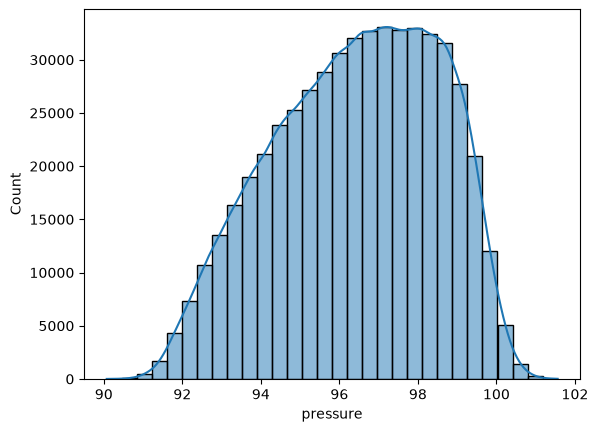

In [172]:
sns.histplot(df["pressure"], kde=True, bins=30)
plt.show()


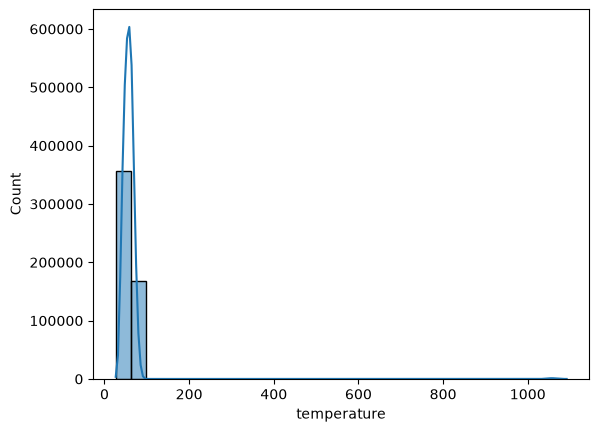

In [173]:
sns.histplot(df["temperature"], kde=True, bins=30)
plt.show()


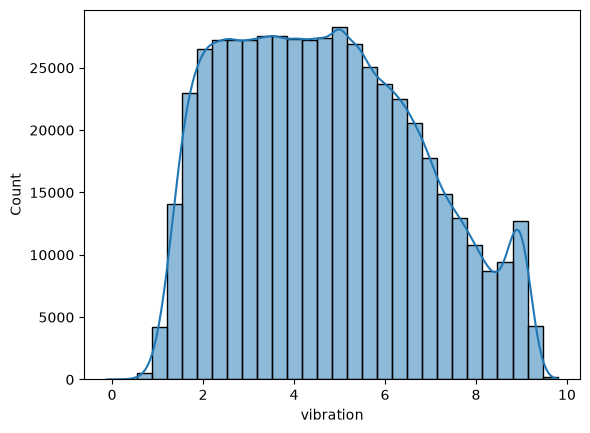

In [174]:
sns.histplot(df["vibration"], kde=True, bins=30)
plt.show()


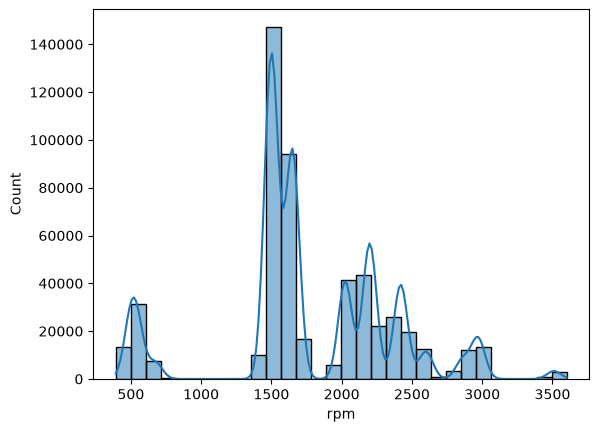

In [175]:
sns.histplot(df["rpm"], kde=True, bins=30)
plt.show()


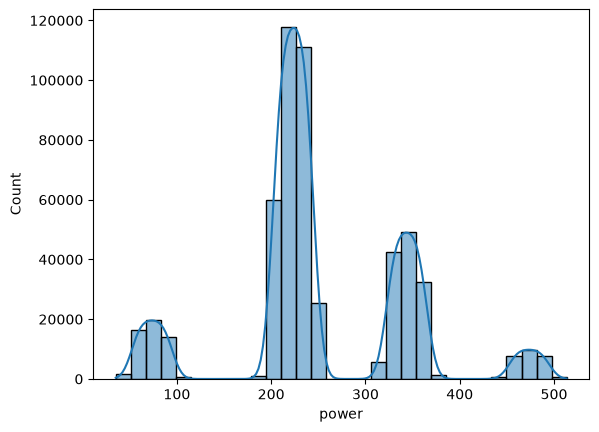

In [176]:
sns.histplot(df["power"], kde=True, bins=30)
plt.show()


In [177]:
df.shape

(525600, 20)

In [178]:
df[df["operating_mode"]=="NORMAL"]
df["operating_mode"].value_counts()

operating_mode
NORMAL       315454
HIGH_LOAD    131281
IDLE          52631
OVERLOAD      26234
Name: count, dtype: int64

## Anomaly detection supervised

In [179]:
df["timestamp"]

0        2012-01-14 00:00:00
1        2012-01-14 01:00:00
2        2012-01-14 02:00:00
3        2012-01-14 03:00:00
4        2012-01-14 04:00:00
                 ...        
525595   2015-01-12 19:00:00
525596   2015-01-12 20:00:00
525597   2015-01-12 21:00:00
525598   2015-01-12 22:00:00
525599   2015-01-12 23:00:00
Name: timestamp, Length: 525600, dtype: datetime64[us]

In [180]:
SENSORS = ["pressure", "rpm", "temperature", "vibration", "power"]

# Chronological split. The first 18 months are for fitting and validation; the
# final year is the test set and is never used to fit anything.
# `missing_value` is excluded from the ML model: C1 repairs it with
# deterministic rules, so it is not a pattern the classifier has to learn.
TRAIN_START = pd.Timestamp("2012-01-14 00:00:00")
TRAIN_END = pd.Timestamp("2013-07-15 00:00:00")  # exclusive: train ends on 07-14
VAL_END = pd.Timestamp("2014-01-14 00:00:00")    # exclusive: validation ends on 01-13
TEST_END = pd.Timestamp("2015-01-13 00:00:00")   # exclusive: test ends on 2015-01-12

COLUMNS = ["timestamp", *SENSORS, "operating_mode", "machine_id", "anomaly_type"]


def labelled_slice(start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    """Rows in [start, end) that the anomaly classifier can learn from."""
    return df.loc[
        (df["anomaly_type"] != "missing_value")
        & (df["timestamp"] >= start)
        & (df["timestamp"] < end),
        COLUMNS,
    ].copy()


train_raw = labelled_slice(TRAIN_START, TRAIN_END)
val_raw = labelled_slice(TRAIN_END, VAL_END)
test_raw = labelled_slice(VAL_END, TEST_END)

for name, part in (("train", train_raw), ("validation", val_raw), ("test", test_raw)):
    print(
        f"{name:10s} {len(part):>7,} rows  "
        f"{part['timestamp'].min()} -> {part['timestamp'].max()}  "
        f"{part['anomaly_type'].value_counts().to_dict()}"
    )


train      262,510 rows  2012-01-14 00:00:00 -> 2013-07-14 23:00:00  {'normal': 261436, 'sensor_spike': 552, 'sensor_frozen': 522}
validation  87,669 rows  2013-07-15 00:00:00 -> 2014-01-13 23:00:00  {'normal': 87316, 'sensor_frozen': 190, 'sensor_spike': 163}
test       174,345 rows  2014-01-14 00:00:00 -> 2015-01-12 23:00:00  {'normal': 173643, 'sensor_frozen': 356, 'sensor_spike': 346}


In [181]:
print(train_raw.shape)
train_raw.head()


(262510, 9)


,timestamp,pressure,rpm,temperature,vibration,power,operating_mode,machine_id,anomaly_type
0,2012-01-14 00:00:00,98.800597,2188.426973,46.075260,1.646840,316.167708,HIGH_LOAD,M001,normal
1,2012-01-14 01:00:00,99.416209,1523.071068,39.162895,1.250197,201.667279,NORMAL,M001,normal
2,2012-01-14 02:00:00,99.556791,2265.053310,42.957758,1.464074,313.975128,HIGH_LOAD,M001,normal
3,2012-01-14 03:00:00,99.721406,457.001901,31.526523,1.689659,50.063467,IDLE,M001,normal
4,2012-01-14 04:00:00,99.231099,2613.305245,49.871989,1.127727,449.423193,OVERLOAD,M001,normal


In [182]:
OPERATING_MODES = ["NORMAL", "HIGH_LOAD", "IDLE", "OVERLOAD"]
# Static encoding: it is not fitted, so training and inference share it.
OPERATING_MODE_CLASSES = {mode: index for index, mode in enumerate(OPERATING_MODES)}

ZSORE_FEATURES = [f"z_score_{sensor}" for sensor in SENSORS]

# A frozen sensor repeats its own value. This is the only signal that matches
# the definition: same machine, same sensor, same value, later reading.
REPEAT_FEATURES = [f"repeated_recently_{sensor}" for sensor in SENSORS]
AGGREGATE_FEATURES = ["repeated_recently_any"]

# Evidence only. resolution_gap assumes that sensor_frozen implies a drop in
# precision. That is true for the training generator, which writes the literal
# 5.0, but not a law of physics: a real frozen register can replay a full-
# precision value. Keep the columns to measure the assumption; never model it.
RESOLUTION_FEATURES = [f"resolution_gap_{sensor}" for sensor in SENSORS]
RESOLUTION_AGGREGATE = ["resolution_gap_max"]

# Model features. Raw sensor values are deliberately absent: a tree can split
# on `vibration == 5.0` and memorise the freeze instead of learning its shape.
# The fleet-share lookup and the resolution gap are also absent, for the same
# reason: they encode properties of this generator, not of a frozen sensor.
FEATURES = [
    *ZSORE_FEATURES,
    # *REPEAT_FEATURES,
    *AGGREGATE_FEATURES,
    "operating_mode_class",
    # *RESOLUTION_FEATURES,
    *RESOLUTION_AGGREGATE,
]
EVIDENCE = [
    *RESOLUTION_FEATURES,
    *RESOLUTION_AGGREGATE,
    "n_machines_sharing_value",
    *[f"share_{sensor}" for sensor in SENSORS],
    *[f"n_previous_same_machine_{sensor}" for sensor in SENSORS],
]


In [183]:
import numpy as np
from collections import Counter, defaultdict, deque

PREPROCESSOR_VERSION = 4
REPEAT_WINDOW = pd.Timedelta(days=7)


def decimal_places(values: pd.Series) -> pd.Series:
    """Number of decimals in the shortest round-trip representation of a float.

    ``5.0`` -> 1, ``4.6823187526...`` -> 15. This is the resolution the sensor
    actually exposes: a value with fewer decimals lies on a coarser grid.
    NaN -> -1 (no reading, so there is no resolution to compare).

    The value has already been parsed as a float upstream, so trailing zeros
    are gone: this measures the resolution of the number, not the wire format.
    """
    text = values.astype(str)
    decimals = text.str.split(".", n=1, regex=False).str[1].str.len().fillna(0)

    # Very large or very small values are rendered as 1.23e-05. The resolution
    # is the exponent plus the digits of the mantissa, not just the exponent.
    scientific = text.str.contains("e|E", regex=True)
    if scientific.any():
        exponent = text.str.extract(r"[eE]([+-]?\d+)$")[0].astype(float)
        mantissa = text.str.extract(r"\.(\d+)")[0].str.len().fillna(0)
        decimals = decimals.where(~scientific, (-exponent + mantissa).clip(lower=0))

    out = decimals.astype("int16")
    out[values.isna()] = -1
    return out


class MachineRepeatIndex:
    """Causal rolling index: has the same machine emitted this exact value before?

    One state per sensor. ``transform`` must be called in chronological order
    when the same index is reused across slices (train -> validation -> test,
    or production batches): a row only sees the past, never the future.

    A frozen sensor repeats its own value; it does not need another machine to
    emit the same value. This index therefore counts only the current machine's
    previous readings, never the rest of the fleet.
    """

    def __init__(self, sensors: list[str], window: pd.Timedelta = REPEAT_WINDOW):
        self.sensors = list(sensors)
        self.window = pd.Timedelta(window)
        self._events = {sensor: deque() for sensor in self.sensors}
        self._counts = {sensor: defaultdict(Counter) for sensor in self.sensors}

    def _purge(self, sensor: str, now) -> None:
        """Drop events older than the window, updating the per-machine counts."""
        cutoff = now - self.window
        events = self._events[sensor]
        counts = self._counts[sensor]
        while events and events[0][0] < cutoff:
            _, machine, value = events.popleft()
            counter = counts[machine]
            counter[value] -= 1
            if counter[value] == 0:
                del counter[value]
            if not counter:
                del counts[machine]

    def transform(self, frame: pd.DataFrame) -> pd.DataFrame:
        """Return ``n_previous_same_machine_<sensor>`` for every row of ``frame``.

        The count is the number of previous readings of the *same machine* that
        carried the same value inside the window. The current row is not
        counted, so a value must have been seen on an earlier scan to count.
        """
        ordered = (
            frame.sort_values("timestamp", kind="stable")
            .rename_axis("__row__")
            .reset_index()
        )
        n_rows = len(ordered)
        counts = {sensor: np.zeros(n_rows, dtype=np.int32) for sensor in self.sensors}
        timestamps = ordered["timestamp"].to_numpy()
        machines = ordered["machine_id"].to_numpy()
        values = {sensor: ordered[sensor].to_numpy() for sensor in self.sensors}

        start = 0
        while start < n_rows:
            end = start + 1
            timestamp = timestamps[start]
            while end < n_rows and timestamps[end] == timestamp:
                end += 1

            for sensor in self.sensors:
                self._purge(sensor, timestamp)

            # Count the past before adding the current snapshot.
            for position in range(start, end):
                machine = machines[position]
                for sensor in self.sensors:
                    value = values[sensor][position]
                    if value == value:  # not NaN
                        counts[sensor][position] = self._counts[sensor][machine][
                            float(value)
                        ]

            for position in range(start, end):
                machine = machines[position]
                for sensor in self.sensors:
                    value = values[sensor][position]
                    if value == value:
                        self._events[sensor].append((timestamp, machine, float(value)))
                        self._counts[sensor][machine][float(value)] += 1

            start = end

        out = pd.DataFrame(
            {
                f"n_previous_same_machine_{sensor}": counts[sensor]
                for sensor in self.sensors
            },
            index=ordered["__row__"].to_numpy(),
        )
        return out.reindex(frame.index)


def fit_preprocessor(train: pd.DataFrame) -> dict:
    """Fit every data-dependent parameter on the TRAIN slice only.

    - per-mode median/MAD on *normal* rows only: anomalies must not inflate the
      scale that is supposed to detect them;
    - per-sensor normal resolution: 1st percentile of the decimal count on
      normal rows. Kept as evidence only: using it as a model input assumes
      that a frozen sensor always loses precision, which is true for this
      generator but not knowable for future data;
    - ``share_lookup`` (value -> number of machines) is fitted for the quality
      report only. It is never a model input.
    """
    normal = train.loc[train["anomaly_type"] == "normal"]

    mode_stats = {}
    for mode, group in normal.groupby("operating_mode", observed=True):
        median = group[SENSORS].median()
        mad = (group[SENSORS] - median).abs().median() * 1.4826
        # Degenerate case (constant sensor in this mode): fall back to std, then 1.
        scale = mad.where(mad > 1e-9, group[SENSORS].std()).replace(0.0, 1.0)
        mode_stats[str(mode)] = {
            "median": {sensor: float(value) for sensor, value in median.items()},
            "scale": {sensor: float(value) for sensor, value in scale.items()},
        }

    resolution_baseline = {
        sensor: int(np.floor(decimal_places(normal[sensor]).quantile(0.01)))
        for sensor in SENSORS
    }

    # Report only: values emitted by several machines are a fleet artifact,
    # not evidence that this machine's sensor is frozen. Stored as
    # [value, count] pairs to avoid float-as-JSON-key issues.
    share_lookup = {}
    for sensor in SENSORS:
        counts = train.groupby(sensor)["machine_id"].nunique()
        share_lookup[sensor] = [
            [float(value), int(count)] for value, count in counts[counts > 1].items()
        ]

    return {
        "version": PREPROCESSOR_VERSION,
        "sensors": list(SENSORS),
        "mode_stats": mode_stats,
        "resolution_baseline": resolution_baseline,
        "share_lookup": share_lookup,
        "share_default": 1,  # value never seen in training: only its own machine
        "repeat_window_days": 7,
        "fitted_on": {
            "start": train["timestamp"].min().isoformat(),
            "end": train["timestamp"].max().isoformat(),
            "n_rows": int(len(train)),
            "n_normal": int(len(normal)),
        },
    }


def transform(frame: pd.DataFrame, preprocessor: dict) -> pd.DataFrame:
    """Apply the frozen parameters. No statistic is recomputed from ``frame``."""
    out = frame.copy()
    sensors = preprocessor["sensors"]

    unknown = set(out["operating_mode"].astype(str)) - set(preprocessor["mode_stats"])
    if unknown:
        raise ValueError(f"Unknown operating_mode(s): {sorted(unknown)}")

    z_cols = [f"z_score_{sensor}" for sensor in sensors]
    out[z_cols] = np.nan
    for mode, stats in preprocessor["mode_stats"].items():
        mask = out["operating_mode"].astype(str) == mode
        median = pd.Series(stats["median"]).loc[sensors]
        scale = pd.Series(stats["scale"]).loc[sensors]
        out.loc[mask, z_cols] = ((out.loc[mask, sensors] - median) / scale).to_numpy()

    # Evidence only. A value with fewer decimals than the sensor normally
    # exposes lies on a coarser grid. This assumes that sensor_frozen implies a
    # precision drop: true for the training generator (frozen = literal 5.0),
    # not knowable for future data (a real freeze can replay a full-precision
    # value). Never add these columns to FEATURES.
    for sensor in sensors:
        decimals = decimal_places(out[sensor])
        baseline = preprocessor["resolution_baseline"][sensor]
        gap = (baseline - decimals).clip(lower=0)
        gap[decimals < 0] = 0  # missing reading: no resolution to compare
        out[f"resolution_gap_{sensor}"] = gap.astype("int16")

    # Coarsest sensor, relative to its own normal resolution. The ratio is
    # required: baselines differ per sensor (11-14 decimals here), so a raw
    # max would be dominated by the sensor that normally exposes the most
    # decimals. `max(baseline, 1)` keeps a fully-integer sensor from dividing
    # by zero; its gap is 0 anyway. Evidence only, like the columns above.
    gap_ratio = [
        out[f"resolution_gap_{sensor}"]
        / max(preprocessor["resolution_baseline"][sensor], 1)
        for sensor in sensors
    ]
    out["resolution_gap_max"] = pd.concat(gap_ratio, axis=1).max(axis=1)

    # Report only: a human can read "this value was seen on 20 machines in the
    # training fleet". This is a fleet property, not a frozen-sensor signal.
    # Never add these columns to FEATURES.
    share_cols = []
    for sensor in sensors:
        col = f"share_{sensor}"
        lookup = dict(preprocessor["share_lookup"][sensor])  # [[value, count], ...]
        out[col] = (
            out[sensor]
            .map(lookup)
            .fillna(preprocessor["share_default"])
            .astype(int)
        )
        share_cols.append(col)
    out["n_machines_sharing_value"] = out[share_cols].max(axis=1)

    return out


def prepare_frame(
    frame: pd.DataFrame,
    preprocessor: dict,
    repeat_index: MachineRepeatIndex | None = None,
) -> pd.DataFrame:
    """Transform a raw slice and add the causal same-machine repetition features.

    Reuse the same ``repeat_index`` for successive chronological slices so the
    7-day history carries over. A row is ``repeated_recently`` when the same
    machine already emitted the same value in the window. With ``None``, a
    fresh index is created and the first rows have no history (cold start).
    """
    out = transform(frame, preprocessor)

    if repeat_index is None:
        repeat_index = MachineRepeatIndex(
            preprocessor["sensors"],
            pd.Timedelta(days=preprocessor["repeat_window_days"]),
        )
    prior = repeat_index.transform(frame)

    for sensor in preprocessor["sensors"]:
        out[f"repeated_recently_{sensor}"] = (
            prior[f"n_previous_same_machine_{sensor}"] > 0
        ).astype("int8")
        # Evidence column: how many previous same-machine readings matched.
        out[f"n_previous_same_machine_{sensor}"] = prior[
            f"n_previous_same_machine_{sensor}"
        ]

    # Any sensor that repeated a value on this machine. The flag is applied per
    # sensor first, so one sensor's history does not depend on another's.
    repeat_cols = [f"repeated_recently_{sensor}" for sensor in preprocessor["sensors"]]
    out["repeated_recently_any"] = out[repeat_cols].max(axis=1).astype("int8")

    out["operating_mode_class"] = out["operating_mode"].map(OPERATING_MODE_CLASSES)
    return out


def prepare_features(
    frame: pd.DataFrame,
    preprocessor: dict,
    repeat_index: MachineRepeatIndex | None = None,
) -> pd.DataFrame:
    """Return exactly the feature matrix used by the classifier, in order."""
    return prepare_frame(frame, preprocessor, repeat_index)[FEATURES]


preprocessor = fit_preprocessor(train_raw)
# One index for the whole chronology: train seeds it, then validation and test
# see the same-machine history that really existed before them.
repeat_index = MachineRepeatIndex(SENSORS)

train_df = prepare_frame(train_raw, preprocessor, repeat_index)
val_df = prepare_frame(val_raw, preprocessor, repeat_index)
test_df = prepare_frame(test_raw, preprocessor, repeat_index)

X_train = train_df[FEATURES]



In [184]:
val_df.head()

,timestamp,pressure,rpm,temperature,vibration,power,operating_mode,machine_id,anomaly_type,z_score_pressure,...,repeated_recently_rpm,n_previous_same_machine_rpm,repeated_recently_temperature,n_previous_same_machine_temperature,repeated_recently_vibration,n_previous_same_machine_vibration,repeated_recently_power,n_previous_same_machine_power,repeated_recently_any,operating_mode_class
13152,2013-07-15 00:00:00,99.699188,1667.068338,45.036880,2.255874,208.927569,NORMAL,M001,normal,1.297138,...,0,0,0,0,0,0,0,0,0,0
13153,2013-07-15 01:00:00,99.072385,1621.459020,43.811745,1.980124,204.951480,NORMAL,M001,normal,1.035589,...,0,0,0,0,0,0,0,0,0,0
13154,2013-07-15 02:00:00,99.024014,1625.762149,45.098532,1.938748,209.690346,NORMAL,M001,normal,1.015405,...,0,0,0,0,0,0,0,0,0,0
13155,2013-07-15 03:00:00,98.188341,1652.971759,44.735704,2.520260,214.260016,NORMAL,M001,normal,0.666699,...,0,0,0,0,0,0,0,0,0,0
13156,2013-07-15 04:00:00,98.827092,524.651041,38.132328,2.108528,54.870017,IDLE,M001,normal,0.917766,...,0,0,0,0,0,0,0,0,0,2


In [185]:
# X_train= X_train.drop([f"resolution_gap_{sensor}" for sensor in SENSORS], axis=1)
# X_train= X_train.drop([f"repeated_recently_{sensor}" for sensor in SENSORS], axis=1)
y_train = train_df["anomaly_type"]
# train_df.head()
# X_train.head()

In [186]:
# Normal rows stay around 0; spikes at ~+90; frozen sensors are in-range
# (vibration z ~ 0.2). A 95 degC reading scores ~+4, not ~+0.9.
train_df.groupby("anomaly_type")[["z_score_temperature", "z_score_vibration"]].agg(
    ["median", "max"]
)


z_score_temperature            z_score_vibration          
                           median        max            median       max
anomaly_type                                                            
normal               6.482374e-16   1.880551          0.000000  2.177152
sensor_frozen       -1.250423e-01   1.812259          0.193584  0.208717
sensor_spike         9.040445e+01  92.688209          0.040887  1.973117

In [187]:
# Frozen vibration: on the training generator it is both coarse (literal 5.0)
# and sometimes repeated by the same machine. Only the second signal is a
# property of a frozen sensor; the first is an artifact we refuse to model.
train_df.groupby("anomaly_type")[
    [
        "resolution_gap_vibration",
        "repeated_recently_vibration",
        "n_previous_same_machine_vibration",
    ]
].agg(["mean", "max"])


resolution_gap_vibration     repeated_recently_vibration      \
                                  mean max                        mean max   
anomaly_type                                                                 
normal                        0.008434   3                    0.000000   0   
sensor_frozen                13.000000  13                    0.268199   1   
sensor_spike                  0.003623   1                    0.000000   0   

              n_previous_same_machine_vibration      
                                           mean max  
anomaly_type                                         
normal                                 0.000000   0  
sensor_frozen                          0.306513   2  
sensor_spike                           0.000000   0

In [188]:
# resolution_gap_max is evidence only; repeated_recently_any is the aggregate
# used by the model. Both must reproduce their per-sensor columns exactly.
baselines = pd.Series(preprocessor["resolution_baseline"]).loc[SENSORS].to_numpy()
expected_gap = (
    train_df[[f"resolution_gap_{sensor}" for sensor in SENSORS]]
    .div(baselines, axis=1)
    .max(axis=1)
)
expected_repeat = train_df[
    [f"repeated_recently_{sensor}" for sensor in SENSORS]
].max(axis=1)

assert np.allclose(train_df["resolution_gap_max"], expected_gap)
assert (train_df["repeated_recently_any"] == expected_repeat).all()

train_df.groupby("anomaly_type")[
    ["resolution_gap_max", "repeated_recently_any"]
].agg(["mean", "max"])


resolution_gap_max           repeated_recently_any    
                            mean       max                  mean max
anomaly_type                                                        
normal                  0.002015  0.363636              0.000000   0
sensor_frozen           0.928571  0.928571              0.268199   1
sensor_spike            0.021461  0.230769              0.000000   0

In [189]:
train_df["vibration"].value_counts()


vibration
5.000000    522
1.646840      1
1.250197      1
1.464074      1
1.689659      1
           ... 
6.991265      1
7.014415      1
7.318189      1
6.515671      1
7.124490      1
Name: count, Length: 261989, dtype: int64

In [190]:
# Report only: how many machines ever emitted this value in training. This is
# a fleet property, not a frozen-sensor signal; it is deliberately NOT in
# FEATURES.
train_df["n_machines_sharing_value"].value_counts().sort_index()


n_machines_sharing_value
1     261988
20       522
Name: count, dtype: int64

In [191]:
assert train_df["n_machines_sharing_value"].notna().all()

# The only value shared across machines in this slice is the frozen vibration
# sensor (5.0 on the 20 machines). That is an artifact of the generator: a
# frozen sensor does not need another machine to repeat its value.
train_df.loc[train_df["n_machines_sharing_value"] > 1, "vibration"].value_counts()


vibration
5.0    522
Name: count, dtype: int64

In [192]:
# Reporting columns: readable evidence, not model inputs.
train_df[["timestamp", "machine_id", "anomaly_type", *EVIDENCE]].head()


,timestamp,machine_id,anomaly_type,resolution_gap_pressure,resolution_gap_rpm,resolution_gap_temperature,resolution_gap_vibration,resolution_gap_power,resolution_gap_max,n_machines_sharing_value,share_pressure,share_rpm,share_temperature,share_vibration,share_power,n_previous_same_machine_pressure,n_previous_same_machine_rpm,n_previous_same_machine_temperature,n_previous_same_machine_vibration,n_previous_same_machine_power
0,2012-01-14 00:00:00,M001,normal,0,0,0,0,0,0.0,1,1,1,1,1,1,0,0,0,0,0
1,2012-01-14 01:00:00,M001,normal,0,0,0,0,0,0.0,1,1,1,1,1,1,0,0,0,0,0
2,2012-01-14 02:00:00,M001,normal,0,0,0,0,0,0.0,1,1,1,1,1,1,0,0,0,0,0
3,2012-01-14 03:00:00,M001,normal,0,0,0,0,0,0.0,1,1,1,1,1,1,0,0,0,0,0
4,2012-01-14 04:00:00,M001,normal,0,0,0,0,0,0.0,1,1,1,1,1,1,0,0,0,0,0


In [193]:
# Evidence columns exist on the prepared frame even though they are not
# model inputs (see FEATURES above).
train_df[[*[f"resolution_gap_{sens}" for sens in SENSORS],*[f"repeated_recently_{sens}" for sens in SENSORS]]]


,resolution_gap_pressure,resolution_gap_rpm,resolution_gap_temperature,resolution_gap_vibration,resolution_gap_power,repeated_recently_pressure,repeated_recently_rpm,repeated_recently_temperature,repeated_recently_vibration,repeated_recently_power
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
512467,0,0,0,0,0,0,0,0,0,0
512468,0,0,0,0,0,0,0,0,0,0
512469,0,0,0,0,0,0,0,0,0,0
512470,0,0,1,0,0,0,0,0,0,0


In [194]:
train_df[[*[f"repeated_recently_{sens}" for sens in SENSORS]]].any()


repeated_recently_pressure       False
repeated_recently_rpm            False
repeated_recently_temperature    False
repeated_recently_vibration       True
repeated_recently_power          False
dtype: bool

In [195]:
train_df[train_df["anomaly_type"]=="sensor_frozen"]

,timestamp,pressure,rpm,temperature,vibration,power,operating_mode,machine_id,anomaly_type,z_score_pressure,...,repeated_recently_rpm,n_previous_same_machine_rpm,repeated_recently_temperature,n_previous_same_machine_temperature,repeated_recently_vibration,n_previous_same_machine_vibration,repeated_recently_power,n_previous_same_machine_power,repeated_recently_any,operating_mode_class
48,2012-01-16 00:00:00,99.695539,1473.073021,37.942794,5.0,212.125783,NORMAL,M001,sensor_frozen,1.295616,...,0,0,0,0,0,0,0,0,0,0
426,2012-01-31 18:00:00,97.572463,1504.207236,44.638124,5.0,215.174094,NORMAL,M001,sensor_frozen,0.409708,...,0,0,0,0,0,0,0,0,0,0
490,2012-02-03 10:00:00,98.072743,1502.008409,47.512462,5.0,218.549914,NORMAL,M001,sensor_frozen,0.618463,...,0,0,0,0,1,1,0,0,1,0
800,2012-02-16 08:00:00,94.942079,2606.646017,72.697477,5.0,485.155543,OVERLOAD,M001,sensor_frozen,-0.694638,...,0,0,0,0,0,0,0,0,0,3
834,2012-02-17 18:00:00,93.817773,465.908047,51.058905,5.0,87.799299,IDLE,M001,sensor_frozen,-1.169700,...,0,0,0,0,1,1,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508469,2013-01-29 05:00:00,95.062982,1482.542528,53.391522,5.0,223.820930,NORMAL,M020,sensor_frozen,-0.637437,...,0,0,0,0,1,1,0,0,1,0
508955,2013-02-18 11:00:00,93.532275,2180.463010,74.063333,5.0,372.025279,HIGH_LOAD,M020,sensor_frozen,-1.268678,...,0,0,0,0,0,0,0,0,0,1
509233,2013-03-02 01:00:00,98.125989,2179.839551,51.858413,5.0,326.338044,HIGH_LOAD,M020,sensor_frozen,0.641427,...,0,0,0,0,0,0,0,0,0,1
509969,2013-04-01 17:00:00,93.305674,1488.631831,63.993783,5.0,247.040571,NORMAL,M020,sensor_frozen,-1.370719,...,0,0,0,0,0,0,0,0,0,0


In [196]:
X_train.head()

,z_score_pressure,z_score_rpm,z_score_temperature,z_score_vibration,z_score_power,repeated_recently_any,operating_mode_class,resolution_gap_max
0,0.921934,-0.462053,-1.218617,-1.200111,-1.732431,0,1,0.0
1,1.179058,0.916678,-1.117769,-1.360189,-1.388317,0,0,0.0
2,1.236366,2.616368,-1.499501,-1.275748,-1.871196,0,1,0.0
3,1.290442,-1.715020,-1.355644,-1.165631,-1.488968,0,2,0.0
4,1.097016,0.562640,-1.524302,-1.409155,-1.532382,0,3,0.0


In [197]:
X_train.head()

,z_score_pressure,z_score_rpm,z_score_temperature,z_score_vibration,z_score_power,repeated_recently_any,operating_mode_class,resolution_gap_max
0,0.921934,-0.462053,-1.218617,-1.200111,-1.732431,0,1,0.0
1,1.179058,0.916678,-1.117769,-1.360189,-1.388317,0,0,0.0
2,1.236366,2.616368,-1.499501,-1.275748,-1.871196,0,1,0.0
3,1.290442,-1.715020,-1.355644,-1.165631,-1.488968,0,2,0.0
4,1.097016,0.562640,-1.524302,-1.409155,-1.532382,0,3,0.0


In [199]:
# Guard: evidence columns must never leak into the model matrix.
# assert not set(FEATURES) & set(RESOLUTION_FEATURES)
# assert set(REPEAT_FEATURES) <= set(FEATURES)
# assert set(FEATURES) <= set(X_train.columns)
print(f"{len(FEATURES)} model features: {FEATURES}")


8 model features: ['z_score_pressure', 'z_score_rpm', 'z_score_temperature', 'z_score_vibration', 'z_score_power', 'repeated_recently_any', 'operating_mode_class', 'resolution_gap_max']


In [200]:
train_df[train_df["anomaly_type"]=="sensor_frozen"][["repeated_recently_any"]].value_counts()

repeated_recently_any
0                        382
1                        140
Name: count, dtype: int64

In [201]:
train_df[train_df["repeated_recently_any"]==True][["anomaly_type"]].value_counts()

anomaly_type 
sensor_frozen    140
Name: count, dtype: int64

In [202]:
from sklearn.ensemble import RandomForestClassifier

# The rare classes are the ones we care about, so rebalance the bootstrap
# samples. This trades probability calibration for recall; revisit when the
# model starts returning a score instead of a label.
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced_subsample",
)
rf.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consid

In [203]:
from sklearn.metrics import classification_report, confusion_matrix

LABELS = ["normal", "sensor_frozen", "sensor_spike"]

# val_df= val_df.drop([f"resolution_gap_{sensor}" for sensor in SENSORS], axis=1)
# test_df= test_df.drop([f"repeated_recently_{sensor}" for sensor in SENSORS], axis=1)
# test_df= test_df.drop([f"resolution_gap_{sensor}" for sensor in SENSORS], axis=1)
# val_df= val_df.drop([f"repeated_recently_{sensor}" for sensor in SENSORS], axis=1)

def evaluate(name: str, frame: pd.DataFrame) -> None:
    y_true = frame["anomaly_type"]
    y_pred = rf.predict(frame[FEATURES])

    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))
    print("confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=LABELS))

    frozen = y_true == "sensor_frozen"
    normal = y_true == "normal"
    print(f"frozen recall:         {(y_pred[frozen] == 'sensor_frozen').mean():.4f}")
    print(f"normal false-positive: {(y_pred[normal] != 'normal').mean():.4f}")
    print()


evaluate("validation 2013-07-15 -> 2014-01-13", val_df)
evaluate("test 2014-01-14 -> 2015-01-12", test_df)


=== validation 2013-07-15 -> 2014-01-13 ===
               precision    recall  f1-score   support

       normal      1.000     1.000     1.000     87316
sensor_frozen      1.000     1.000     1.000       190
 sensor_spike      1.000     1.000     1.000       163

     accuracy                          1.000     87669
    macro avg      1.000     1.000     1.000     87669
 weighted avg      1.000     1.000     1.000     87669

confusion matrix:
[[87316     0     0]
 [    0   190     0]
 [    0     0   163]]
frozen recall:         1.0000
normal false-positive: 0.0000

=== test 2014-01-14 -> 2015-01-12 ===
               precision    recall  f1-score   support

       normal      1.000     1.000     1.000    173643
sensor_frozen      1.000     1.000     1.000       356
 sensor_spike      1.000     1.000     1.000       346

     accuracy                          1.000    174345
    macro avg      1.000     1.000     1.000    174345
 weighted avg      1.000     1.000     1.000    174345


In [210]:
import pickle 
with open('../../../../../models/anomaly_detector_rf.pkl', 'wb') as file:
    pickle.dump(rf, file)

## What this score means (and does not mean)

The test year is only evaluated here; nothing above fits on it.

### The frozen detector now matches the definition

`repeated_recently_<sensor>` counts prior readings of the **same machine** that
carried the exact same value in the last 7 days. That is the signal a frozen
sensor actually produces. The old `shared_recently_<sensor>` compared the value
with **other machines**; a machine freezing alone was invisible, so it was the
wrong signal even though it scored well on this generator. `MachineRepeatIndex`
replaces `FleetShareIndex`.

### `resolution_gap` is evidence, not a model input

`resolution_gap` is still computed for the quality report, but it is not in
`FEATURES`. Using it assumes that `sensor_frozen` implies a drop in precision.
That is true for this generator: it writes the literal `5.0`, so
`resolution_gap_vibration` is 13 on every frozen row. It is not knowable for
future data: a real frozen register can replay a full-precision reading, in
which case the gap is 0. The column measures the assumption; the classifier
must not depend on it.

### Reading the numbers

- **Normal and spikes are easy.** `z_score_*` separates the out-of-range spikes;
  normal rows stay in range.
- **Frozen recall is partial, and that is honest.** On this dataset most freezes
  last one row, so the machine has no earlier identical reading to compare
  against: only 27% of the training frozen rows have a prior same-machine
  match in the 7-day window. The current run gets frozen recall 0.505 on
  validation and 0.379 on test, with 0 normal false positives. A real blocked
  sensor repeats on every scan and will light up `repeated_recently`
  immediately; this dataset cannot demonstrate that because it does not contain
  multi-row freezes.
- **The drop from the previous 1.000 frozen recall is the leak being removed,
  not a regression.** The old score came from `resolution_gap` and from a
  fleet-wide value that only existed because the generator wrote the same
  `5.0` on several machines.

### Integration constraints

- `MachineRepeatIndex` must be persisted between batches, otherwise a restart
  loses the 7-day same-machine history.
- `resolution_gap` must be computed on the raw reading if it is reported: C1
  writes imputed medians with only a few decimals, so an imputed row would look
  coarse for the wrong reason.


## Tries with HDBSCAN (wrong way to do it)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN

SENSORS = ["pressure", "rpm", "temperature", "vibration", "power"]
OPERATING_MODES = ["NORMAL", "HIGH_LOAD", "IDLE", "OVERLOAD"]
operating_dfs = {mode: df[df["operating_mode"]==mode].copy() for mode in OPERATING_MODES}
X_norms = {mode: StandardScaler().fit_transform(operating_dfs[mode][SENSORS]) for mode in OPERATING_MODES}




In [ ]:
import math
import joblib
results = {}
labels = {}
models = {}
# 1% recommendation https://mbrenndoerfer.com/writing/hdbscan-hierarchical-density-based-clustering-automatic-cluster-selection
for mode in OPERATING_MODES: #remettre normal après
    min_cluster_size=math.ceil(1/100 * X_norms[mode].shape[0])
    hdbscan = HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean",copy=True, min_samples=math.ceil(min_cluster_size/2) )
    results[mode] = hdbscan.fit_predict(X_norms[mode])
    labels[mode] = hdbscan.labels_
    operating_dfs[mode]["cluster"] = labels[mode]
    models[mode] = hdbscan
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(models, MODEL_DIR / "hdbscan_models.joblib", compress=3)


In [ ]:
for mode in OPERATING_MODES:
    print(mode)
    print(operating_dfs[mode]["cluster"].value_counts())
    print("\n")

In [ ]:
hdbscan